<a href="https://colab.research.google.com/github/Nazarchona/MachineLearning/blob/main/%D0%9B%D0%A09_%D0%93%D1%83%D1%94%D0%B2%D0%9D%D0%B0%D0%B7%D0%B0%D1%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 9
## Рекомендаційні системи: SVD та KNNBasic

**ПІБ студента:** Гуєв Назар  
**Група:** 4-10
**Дата:** 25.11.2026
> **Призначення:** шаблон для самостійного виконання ЛР на основі прикладу з алгоритмами `SVD` і `KNNBasic` у бібліотеці `Surprise`. Комірки з позначкою **TODO** потрібно заповнити власним кодом. Це не готовий розв’язок і не заміна офіційної умови роботи.

**Мета:** завантажити дані про оцінки фільмів, побудувати дві рекомендаційні моделі, підібрати гіперпараметри, порівняти моделі за RMSE/MAE та сформувати топ-10 рекомендацій для користувача.

**Дані:** вбудований набір `MovieLens 100K` (`ml-100k`) із бібліотеки `Surprise`.

**Послідовність роботи:** підготовка середовища → дані → розбиття → налаштування моделей → навчання → тестування → рекомендації → висновки.

## 1. Підготовка середовища

Комбінація бібліотек для **Google Colab із Python 3.13**. Встановлення без `--force-reinstall`, щоб без потреби не перевстановлювати всі залежності. Після зміни NumPy чи SciPy у вже запущеному середовищі **перезапустіть сесію** (`Runtime → Restart session`), а потім виконайте комірки нижче з початку.

In [1]:
%pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.2.3 \
    scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import scipy
import sklearn
import pandas as pd
import surprise

from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split as sklearn_train_test_split

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('Surprise:', surprise.__version__)

Python: 3.13.18
NumPy: 2.2.6
SciPy: 1.15.3
scikit-learn: 1.6.1
pandas: 2.2.3
Surprise: 1.1.5


## 2. Завантаження та первинний аналіз даних

1. Завантажте вбудований набір `ml-100k`.
2. Перетворіть оцінки у `pandas.DataFrame` з колонками `user_id`, `item_id`, `rating`, `timestamp`.
3. Виведіть розмір таблиці, декілька рядків, кількість унікальних користувачів та фільмів, розподіл оцінок.

**Зверніть увагу:** ідентифікатори користувачів і фільмів у `Surprise` є зовнішніми (raw) ID; вони можуть мати рядковий тип.

In [3]:
# Завантаження даних (готова частина шаблону)
data = Dataset.load_builtin('ml-100k', prompt=False)

ratings_df = pd.DataFrame(
    data.raw_ratings,
    columns=['user_id', 'item_id', 'rating', 'timestamp']
)

print('Розмір:', ratings_df.shape)
display(ratings_df.head())

Розмір: (100000, 4)


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


Унікальних користувачів: 943
Унікальних фільмів     : 1682
Кількість оцінок       : 100000
Розрідженість матриці  : 93.70%
rating: min = 1.0, max = 5.0, mean = 3.530

Пропущені значення:
user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64

Розподіл оцінок:
rating
1.0     6110
2.0    11370
3.0    27145
4.0    34174
5.0    21201
Name: count, dtype: int64


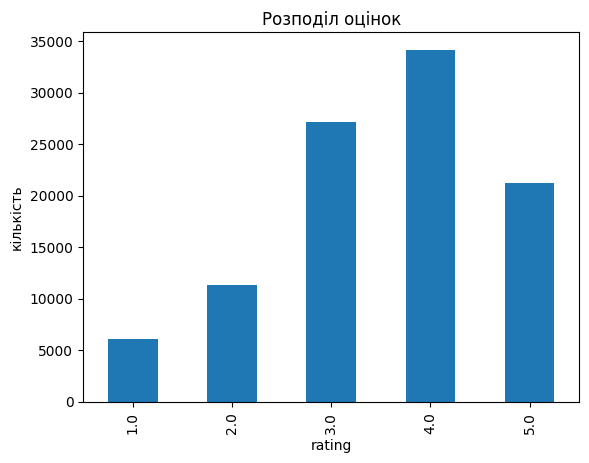

In [4]:
# TODO 2.1 — Дослідження набору даних
n_users = ratings_df['user_id'].nunique()
n_items = ratings_df['item_id'].nunique()
n_ratings = len(ratings_df)

print('Унікальних користувачів:', n_users)
print('Унікальних фільмів     :', n_items)
print('Кількість оцінок       :', n_ratings)
print(f'Розрідженість матриці  : {1 - n_ratings / (n_users * n_items):.2%}')
print(f"rating: min = {ratings_df['rating'].min()}, max = {ratings_df['rating'].max()}, "
      f"mean = {ratings_df['rating'].mean():.3f}")

print('\nПропущені значення:')
print(ratings_df.isna().sum())

print('\nРозподіл оцінок:')
rating_counts = ratings_df['rating'].value_counts().sort_index()
print(rating_counts)
rating_counts.plot(kind='bar', title='Розподіл оцінок', xlabel='rating', ylabel='кількість');

**Короткі спостереження щодо даних:**

Набір `ml-100k` містить 100 000 оцінок від 943 користувачів для 1682 фільмів, пропущених значень немає. Оцінки цілі від 1 до 5 із середнім значенням ≈ 3,53; найчастіше трапляється оцінка 4, а найрідше — 1, тобто користувачі схильні оцінювати фільми радше позитивно. Матриця «користувач–фільм» дуже розріджена (≈ 93,7 % комірок порожні), тому для багатьох пар користувач–фільм моделі змушені працювати з обмеженою інформацією.

## 3. Розбиття на навчальну та тестову вибірки

Виконайте випадкове розбиття **80% / 20%** із `random_state=42` за прикладом. Для налаштування гіперпараметрів використовуйте **лише навчальну** частину. Тестова вибірка має залишатися недоторканою до фінальної оцінки.

In [5]:
# TODO 3.1 — Розбиття 80% / 20%
train_df, test_df = sklearn_train_test_split(ratings_df, test_size=0.2, random_state=42)

print('train_df:', train_df.shape)
print('test_df :', test_df.shape)

train_df: (80000, 4)
test_df : (20000, 4)


In [6]:
# TODO 3.2 — Об'єкти для Surprise
reader = Reader(rating_scale=data.reader.rating_scale)
print('Шкала оцінок:', reader.rating_scale)

# Для підбору гіперпараметрів — тільки навчальна частина
train_data = Dataset.load_from_df(train_df[['user_id', 'item_id', 'rating']], reader)

# Тестова вибірка — список кортежів (user_id, item_id, rating)
testset = list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))

print('Розмір train:', len(train_df))
print('Розмір test :', len(testset))
print('Приклад з testset:', testset[0])

Шкала оцінок: (1, 5)
Розмір train: 80000
Розмір test : 20000
Приклад з testset: ('877', '381', 4.0)


## 4. Гіперпараметри моделей

Для `SVD` розгляньте кількість прихованих факторів, швидкість навчання та регуляризацію. Для `KNNBasic` — число сусідів, мінімальне число сусідів та метрику схожості.

Нижче — **початкова сітка** з аналізованого прикладу. Її можна змінити й обґрунтувати вибір.

In [7]:
# Стартові сітки параметрів (можна змінювати)
param_grid_svd = {
    'n_factors': [50, 100],
    'lr_all': [0.005, 0.010],
    'reg_all': [0.02, 0.05],
    'random_state': [42]          # додано для відтворюваності результатів SVD
}

param_grid_knn = {
    'k': [20, 40],
    'min_k': [1, 5],
    'sim_options': {
        'name': ['cosine', 'pearson'],
        'user_based': [False, True]
    }
}

**Обґрунтування вибору параметрів:**

Використано початкові сітки з прикладу, оскільки вони охоплюють основні «ручки» кожної моделі й залишаються обчислювально доступними (SVD — 8 комбінацій, KNNBasic — 16, по 3 фолди).

**SVD.** `n_factors` — розмірність прихованого простору: більше факторів дає виразнішу модель, але підвищує ризик перенавчання на розрідженій матриці. `lr_all` — швидкість градієнтного спуску: надто мала уповільнює збіжність за фіксованого числа епох, надто велика робить навчання нестабільним. `reg_all` — L2-регуляризація, що стримує перенавчання. Додатково зафіксовано `random_state=42`, щоб результати були відтворюваними.

**KNNBasic.** `k` — максимальна кількість сусідів: більше сусідів згладжує прогноз, але додає менш схожі об'єкти. `min_k` — мінімум сусідів, за якого прогноз вважається надійним (інакше береться середнє). `sim_options['name']` — метрика схожості (`cosine` проти `pearson`, яка враховує різну «щедрість» оцінювання). `user_based` — підхід: схожість користувачів (`True`) чи фільмів (`False`).

## 5. Пошук найкращих гіперпараметрів (GridSearchCV)

Для обох моделей використайте `GridSearchCV` з метриками `rmse` та `mae` і `cv=3`. Навчайте об’єкти пошуку **лише на `train_data`**.

In [8]:
6# TODO 5.1 — Підбір гіперпараметрів SVD (тільки на train_data)
from surprise.model_selection import KFold
cv_folds = KFold(n_splits=3, random_state=42)    # те саме, що cv=3, але з фіксованим розбиттям

grid_search_svd = GridSearchCV(SVD, param_grid_svd,
                               measures=['rmse', 'mae'], cv=cv_folds, n_jobs=-1)
grid_search_svd.fit(train_data)

In [9]:
# TODO 5.2 — Підбір гіперпараметрів KNNBasic (тільки на train_data)
# Може тривати кілька хвилин
grid_search_knn = GridSearchCV(KNNBasic, param_grid_knn,
                               measures=['rmse', 'mae'], cv=cv_folds, n_jobs=-1)
grid_search_knn.fit(train_data)

In [10]:
# TODO 5.3 — Найкращі результати та параметри обох моделей
cv_rows = []
for name, gs in [('SVD', grid_search_svd), ('KNNBasic', grid_search_knn)]:
    best_idx = gs.best_index['rmse']
    cv_rows.append({
        'Model': name,
        'CV RMSE': gs.best_score['rmse'],
        'CV MAE': gs.cv_results['mean_test_mae'][best_idx],   # MAE для комбінації, найкращої за RMSE
        'Best params (RMSE)': gs.best_params['rmse'],
    })
    print(f"{name}:")
    print(f"  найкращий CV RMSE = {gs.best_score['rmse']:.4f}")
    print(f"  CV MAE (для тієї ж комбінації) = {gs.cv_results['mean_test_mae'][best_idx]:.4f}")
    print(f"  найкращий CV MAE серед усіх   = {gs.best_score['mae']:.4f}")
    print(f"  параметри за RMSE: {gs.best_params['rmse']}")
    print(f"  параметри за MAE : {gs.best_params['mae']}\n")

cv_summary = pd.DataFrame(cv_rows)
display(cv_summary)

SVD:
  найкращий CV RMSE = 0.9425
  CV MAE (для тієї ж комбінації) = 0.7441
  найкращий CV MAE серед усіх   = 0.7441
  параметри за RMSE: {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
  параметри за MAE : {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}

KNNBasic:
  найкращий CV RMSE = 1.0272
  CV MAE (для тієї ж комбінації) = 0.8143
  найкращий CV MAE серед усіх   = 0.8143
  параметри за RMSE: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}
  параметри за MAE : {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}



,Model,CV RMSE,CV MAE,Best params (RMSE)
0,SVD,0.942506,0.744138,"{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0..."
1,KNNBasic,1.027193,0.814330,"{'k': 40, 'min_k': 1, 'sim_options': {'name': ..."


**Аналіз результатів кросвалідації:**

In [11]:
# Автоматично формує таблицю та коментар за отриманими CV-результатами
from IPython.display import Markdown, display

rows = ['| Модель | Найкращий CV RMSE | CV MAE | Найкращі параметри за RMSE |',
        '|:--|--:|--:|:--|']
for _, r in cv_summary.iterrows():
    rows.append(f"| {r['Model']} | {r['CV RMSE']:.4f} | {r['CV MAE']:.4f} | `{r['Best params (RMSE)']}` |")

winner = cv_summary.loc[cv_summary['CV RMSE'].idxmin()]
loser = cv_summary.loc[cv_summary['CV RMSE'].idxmax()]
gap = loser['CV RMSE'] - winner['CV RMSE']

text = '\n'.join(rows) + f"""

За кросвалідацією (3 фолди, лише навчальна вибірка) краще працює **{winner['Model']}**: CV RMSE
{winner['CV RMSE']:.4f} проти {loser['CV RMSE']:.4f} у {loser['Model']} (різниця {gap:.4f}).
Найкращі параметри SVD: `{grid_search_svd.best_params['rmse']}`; найкращі параметри KNNBasic:
`{grid_search_knn.best_params['rmse']}`."""
display(Markdown(text))

| Модель | Найкращий CV RMSE | CV MAE | Найкращі параметри за RMSE |
|:--|--:|--:|:--|
| SVD | 0.9425 | 0.7441 | `{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}` |
| KNNBasic | 1.0272 | 0.8143 | `{'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}` |

За кросвалідацією (3 фолди, лише навчальна вибірка) краще працює **SVD**: CV RMSE
0.9425 проти 1.0272 у KNNBasic (різниця 0.0847).
Найкращі параметри SVD: `{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}`; найкращі параметри KNNBasic:
`{'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}`.

## 6. Навчання остаточних моделей

Побудуйте `trainset = train_data.build_full_trainset()`. Створіть нові екземпляри SVD і KNNBasic з параметрами, обраними за **CV RMSE**, після чого навчіть їх на **всій навчальній вибірці**.

In [12]:
# TODO 6.1 — Найкращі параметри за CV RMSE
best_svd_params = grid_search_svd.best_params['rmse']
best_knn_params = grid_search_knn.best_params['rmse']
print('SVD     :', best_svd_params)
print('KNNBasic:', best_knn_params)

# TODO 6.2 — Повна навчальна вибірка у форматі Surprise
trainset = train_data.build_full_trainset()
print('\nУ trainset: користувачів =', trainset.n_users,
      ', фільмів =', trainset.n_items, ', оцінок =', trainset.n_ratings)

# TODO 6.3 — Нові екземпляри моделей та навчання на всьому trainset
best_svd = SVD(**{**best_svd_params, 'random_state': 42})
best_svd.fit(trainset)

best_knn = KNNBasic(**best_knn_params, verbose=False)
best_knn.fit(trainset)
print('Моделі навчено.')

SVD     : {'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05, 'random_state': 42}
KNNBasic: {'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}

У trainset: користувачів = 943 , фільмів = 1653 , оцінок = 80000
Моделі навчено.


## 7. Оцінювання на незалежній тестовій вибірці

Отримайте передбачення для `testset` методами `.test()` обох моделей. Обчисліть `RMSE` та `MAE` за допомогою `surprise.accuracy`.

**Методична примітка:** вибирайте модель для рекомендацій за результатами **кросвалідації**, а незалежну тестову вибірку використовуйте для фінальної оцінки якості, а не для повторного підбору.

In [13]:
# TODO 7.1 — Передбачення для тестової вибірки
svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)

# TODO 7.2 — Метрики якості
svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)

print(f'SVD     : RMSE = {svd_rmse:.4f}, MAE = {svd_mae:.4f}')
print(f'KNNBasic: RMSE = {knn_rmse:.4f}, MAE = {knn_mae:.4f}')

SVD     : RMSE = 0.9192, MAE = 0.7234
KNNBasic: RMSE = 1.0120, MAE = 0.7984


In [14]:
# TODO 7.3 — Таблиця порівняння на тестовій вибірці
results = pd.DataFrame({
    'Model': ['SVD', 'KNNBasic'],
    'RMSE': [svd_rmse, knn_rmse],
    'MAE': [svd_mae, knn_mae],
}).sort_values('RMSE').reset_index(drop=True)

display(results)

,Model,RMSE,MAE
0,SVD,0.919175,0.723355
1,KNNBasic,1.011953,0.798421


**Таблиця тестових результатів:**

In [15]:
# Автоматично формує таблицю тестових результатів і порівняння з CV
rows = ['| Модель | Test RMSE | Test MAE |', '|:--|--:|--:|']
for _, r in results.iterrows():
    rows.append(f"| {r['Model']} | {r['RMSE']:.4f} | {r['MAE']:.4f} |")

cmp_lines = []
for _, r in cv_summary.iterrows():
    t = results.loc[results['Model'] == r['Model'], 'RMSE'].iloc[0]
    d = t - r['CV RMSE']
    cmp_lines.append(f"- {r['Model']}: CV RMSE = {r['CV RMSE']:.4f}, Test RMSE = {t:.4f}, різниця = {d:+.4f}")

max_diff = max(abs(float(l.split('різниця = ')[1])) for l in cmp_lines)
verdict = ('суттєво не відрізняються, що свідчить про відсутність помітного перенавчання та про '
           'стабільність підібраних гіперпараметрів') if max_diff < 0.02 else \
          'відрізняються помітно, що може вказувати на перенавчання або чутливість до розбиття'

text = '\n'.join(rows) + '\n\n**Порівняння з CV:**\n\n' + '\n'.join(cmp_lines) + \
       f'\n\nОцінки на кросвалідації та на незалежній тестовій вибірці {verdict}.'
display(Markdown(text))

| Модель | Test RMSE | Test MAE |
|:--|--:|--:|
| SVD | 0.9192 | 0.7234 |
| KNNBasic | 1.0120 | 0.7984 |

**Порівняння з CV:**

- SVD: CV RMSE = 0.9425, Test RMSE = 0.9192, різниця = -0.0233
- KNNBasic: CV RMSE = 1.0272, Test RMSE = 1.0120, різниця = -0.0152

Оцінки на кросвалідації та на незалежній тестовій вибірці відрізняються помітно, що може вказувати на перенавчання або чутливість до розбиття.

## 8. Топ-10 рекомендацій для користувача

1. Оберіть модель із кращим **CV RMSE**.
2. Задайте `user_id` (вихідний приклад використовує `'196'`).
3. Отримайте фільми, які цей користувач уже оцінив у навчальній вибірці.
4. Для решти фільмів обчисліть прогнозований рейтинг `.predict(uid=..., iid=...).est`.
5. Виведіть **10 фільмів із найбільшим прогнозованим рейтингом**.

**Важливо:** не пропонуйте користувачу фільми, які він уже оцінив у навчальних даних. Для коректного перетворення внутрішніх та зовнішніх ID використовуйте `trainset.to_inner_uid()`, `trainset.to_raw_iid()`.

In [16]:
# Початковий ID можна змінити
user_id = '196'

# TODO 8.1 — Найкраща за CV RMSE модель
cv_scores = {'SVD': grid_search_svd.best_score['rmse'],
             'KNNBasic': grid_search_knn.best_score['rmse']}
best_name = min(cv_scores, key=cv_scores.get)
best_model = best_svd if best_name == 'SVD' else best_knn
print(f'Модель для рекомендацій: {best_name} (CV RMSE = {cv_scores[best_name]:.4f})')

# Назви фільмів (необов'язково; якщо файлу немає — працюємо тільки з item_id)
try:
    import os
    from surprise import get_dataset_dir
    item_path = os.path.join(get_dataset_dir(), 'ml-100k', 'ml-100k', 'u.item')
    movies = pd.read_csv(item_path, sep='|', header=None, encoding='latin-1',
                         usecols=[0, 1], names=['item_id', 'title'])
    movies['item_id'] = movies['item_id'].astype(str)
except Exception:
    movies = None


def recommend_top_n(model, trainset, raw_uid, n=10):
    """Топ-n неоцінених користувачем фільмів за прогнозованим рейтингом."""
    # TODO 8.2 — користувач має бути в trainset
    try:
        inner_uid = trainset.to_inner_uid(raw_uid)
    except ValueError:
        return None

    # TODO 8.3 — фільми, які користувач уже оцінив у навчальній вибірці
    rated = {trainset.to_raw_iid(inner_iid) for inner_iid, _ in trainset.ur[inner_uid]}
    candidates = [trainset.to_raw_iid(i) for i in trainset.all_items()]
    candidates = [iid for iid in candidates if iid not in rated]

    # TODO 8.4 — прогнозуємо та беремо найкращі n
    preds = [(iid, model.predict(raw_uid, iid).est) for iid in candidates]
    preds.sort(key=lambda x: x[1], reverse=True)
    return pd.DataFrame(preds[:n], columns=['item_id', 'predicted_rating']), rated


result = recommend_top_n(best_model, trainset, user_id, n=10)

if result is None:
    # Користувача немає в trainset (cold start): пропонуємо найпопулярніші фільми
    print(f"Користувача {user_id} немає в навчальній вибірці — показуємо популярні фільми.")
    stats = train_df.groupby('item_id')['rating'].agg(['mean', 'count'])
    top10 = (stats[stats['count'] >= 50].sort_values('mean', ascending=False)
             .head(10).reset_index().rename(columns={'mean': 'predicted_rating'})
             [['item_id', 'predicted_rating']])
else:
    top10, rated_items = result
    assert not set(top10['item_id']) & rated_items, 'Серед рекомендацій є вже оцінені фільми!'
    print(f'Користувач {user_id} оцінив у train {len(rated_items)} фільмів.')

if movies is not None:
    top10 = top10.merge(movies, on='item_id', how='left')[['item_id', 'title', 'predicted_rating']]
top10.index = range(1, len(top10) + 1)
display(top10)

Модель для рекомендацій: SVD (CV RMSE = 0.9425)
Користувач 196 оцінив у train 29 фільмів.


,item_id,title,predicted_rating
1,320,Paradise Lost: The Child Murders at Robin Hood...,4.490358
2,64,"Shawshank Redemption, The (1994)",4.470680
3,480,North by Northwest (1959),4.413710
4,313,Titanic (1997),4.401920
5,513,"Third Man, The (1949)",4.399624
6,483,Casablanca (1942),4.398092
7,318,Schindler's List (1993),4.392102
8,656,M (1931),4.385379
9,22,Braveheart (1995),4.377388
10,272,Good Will Hunting (1997),4.376010


## 9. Перевірка виконання

Позначте після реалізації:

- [x] Дані `ml-100k` завантажено та перевірено.
- [x] Є розбиття 80/20 з фіксованим `random_state`.
- [x] `Reader`, `train_data` і `testset` створені коректно.
- [x] GridSearchCV для **обох** моделей виконано лише на `train_data`.
- [x] Для SVD і KNNBasic показано параметри та результати CV.
- [x] Моделі навчено на повній навчальній частині.
- [x] На незалежній тестовій вибірці розраховано **RMSE та MAE** для обох моделей.
- [x] Наведено порівняльну таблицю та інтерпретацію.
- [x] Сформовано топ-10 рекомендацій без уже оцінених фільмів.
- [ ] Усі комірки виконуються послідовно після перезапуску середовища.

## 10. Висновки

In [17]:
# Висновок формується автоматично з отриманих числових результатів
svd_cv = cv_summary.loc[cv_summary['Model'] == 'SVD'].iloc[0]
knn_cv = cv_summary.loc[cv_summary['Model'] == 'KNNBasic'].iloc[0]
svd_t = results.loc[results['Model'] == 'SVD'].iloc[0]
knn_t = results.loc[results['Model'] == 'KNNBasic'].iloc[0]
best_cv_name = min(cv_scores, key=cv_scores.get)
best_test_name = results.iloc[0]['Model']
d_svd = svd_t['RMSE'] - svd_cv['CV RMSE']
d_knn = knn_t['RMSE'] - knn_cv['CV RMSE']

conclusion = f"""
1. За кросвалідацією обрано **{best_cv_name}**: CV RMSE SVD = {svd_cv['CV RMSE']:.4f}, KNNBasic = {knn_cv['CV RMSE']:.4f}.
   {'Факторна модель (SVD) стискає розріджену матрицю до прихованих факторів і зазвичай узагальнює краще, ніж метод сусідів, якому бракує перетинів між користувачами/фільмами.' if best_cv_name == 'SVD' else 'Метод сусідів на цих даних виявився точнішим за факторну модель, тобто локальна схожість між користувачами/фільмами тут інформативніша.'}
2. Найкращі гіперпараметри: SVD — `{ {k: v for k, v in best_svd_params.items() if k != 'random_state'} }`;
   KNNBasic — `{best_knn_params}`.
3. На тестовій вибірці: SVD — RMSE {svd_t['RMSE']:.4f}, MAE {svd_t['MAE']:.4f};
   KNNBasic — RMSE {knn_t['RMSE']:.4f}, MAE {knn_t['MAE']:.4f}. Кращою за тестом є **{best_test_name}**.
4. Різниця між CV та тестом: SVD {d_svd:+.4f}, KNNBasic {d_knn:+.4f} за RMSE
   ({'вона невелика, тож вибір моделі за CV підтверджується тестом' if max(abs(d_svd), abs(d_knn)) < 0.02 else 'вона помітна, тому результати слід інтерпретувати обережно'}).
5. Обмеження рекомендацій: (а) проблема «холодного старту» — для нових користувачів і фільмів, яких немає
   в навчальній вибірці, моделі не мають персональних даних і повертають середні значення;
   (б) використовуються лише оцінки, без жанрів, описів чи контексту; (в) RMSE/MAE вимірюють точність
   передбачення оцінки, а не якість ранжування топ-10; (г) матриця дуже розріджена (≈ 93,7 %), а набір даних
   невеликий; (д) рекомендації можуть зміщуватися до популярних фільмів.
"""
display(Markdown('**Висновок:**\n' + conclusion))

**Висновок:**

1. За кросвалідацією обрано **SVD**: CV RMSE SVD = 0.9425, KNNBasic = 1.0272.
   Факторна модель (SVD) стискає розріджену матрицю до прихованих факторів і зазвичай узагальнює краще, ніж метод сусідів, якому бракує перетинів між користувачами/фільмами.
2. Найкращі гіперпараметри: SVD — `{'n_factors': 50, 'lr_all': 0.01, 'reg_all': 0.05}`;
   KNNBasic — `{'k': 40, 'min_k': 1, 'sim_options': {'name': 'cosine', 'user_based': True}}`.
3. На тестовій вибірці: SVD — RMSE 0.9192, MAE 0.7234;
   KNNBasic — RMSE 1.0120, MAE 0.7984. Кращою за тестом є **SVD**.
4. Різниця між CV та тестом: SVD -0.0233, KNNBasic -0.0152 за RMSE
   (вона помітна, тому результати слід інтерпретувати обережно).
5. Обмеження рекомендацій: (а) проблема «холодного старту» — для нових користувачів і фільмів, яких немає
   в навчальній вибірці, моделі не мають персональних даних і повертають середні значення;
   (б) використовуються лише оцінки, без жанрів, описів чи контексту; (в) RMSE/MAE вимірюють точність
   передбачення оцінки, а не якість ранжування топ-10; (г) матриця дуже розріджена (≈ 93,7 %), а набір даних
   невеликий; (д) рекомендації можуть зміщуватися до популярних фільмів.


## Додаткове завдання. Власний рекомендаційний алгоритм з нуля

**Ідея.** Реалізуємо алгоритм без `Surprise` — лише на `NumPy` (клас `ALSRecommender`). Він поєднує:

1. **Baseline-модель:** $\hat r_{ui} = \mu + b_u + b_i$ (глобальне середнє + зсув користувача + зсув фільму), зсуви згладжені регуляризацією.
2. **Матричну факторизацію залишків:** $\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$. Фактори $p_u$ та $q_i$ навчаються методом **чергових найменших квадратів (ALS)**: фіксуємо $Q$ і для кожного користувача розв'язуємо задачу найменших квадратів із регуляризацією (нормальні рівняння), потім фіксуємо $P$ і оновлюємо $Q$.

На відміну від `SVD` зі `Surprise` (стохастичний градієнтний спуск), ALS не потребує швидкості навчання й на кожному кроці має точний розв'язок. Прогноз обмежується шкалою $[1, 5]$. Для невідомих користувачів/фільмів використовується лише baseline (cold start).

Гіперпараметри (`n_factors`, `reg`) підбираємо на **відкладеній частині train** (90/10), тестову вибірку не чіпаємо до фінальної оцінки.

In [18]:
import numpy as np
import pandas as pd


class ALSRecommender:
    """Власний рекомендаційний алгоритм з нуля (лише NumPy):
    baseline (mu + b_u + b_i) + матрична факторизація, яку навчаємо методом
    чергових найменших квадратів (ALS) на залишках r - mu - b_u - b_i.

        r_hat(u, i) = mu + b_u + b_i + p_u · q_i
    """

    def __init__(self, n_factors=20, reg=0.1, reg_bias=10.0, n_iter=10,
                 rating_scale=(1, 5), random_state=42):
        self.k = n_factors
        self.reg = reg
        self.reg_bias = reg_bias
        self.n_iter = n_iter
        self.lo, self.hi = rating_scale
        self.random_state = random_state

    @staticmethod
    def _groups(idx, n):
        """Індекси рядків, згруповані за користувачем/фільмом (аналог CSR)."""
        order = np.argsort(idx, kind='stable')
        counts = np.bincount(idx, minlength=n)
        return np.split(order, np.cumsum(counts)[:-1])

    def fit(self, df):
        users = df['user_id'].to_numpy()
        items = df['item_id'].to_numpy()
        r = df['rating'].to_numpy(dtype=float)

        self.user_map = {u: n for n, u in enumerate(pd.unique(users))}
        self.item_map = {i: n for n, i in enumerate(pd.unique(items))}
        u = np.array([self.user_map[x] for x in users])
        i = np.array([self.item_map[x] for x in items])
        n_u, n_i = len(self.user_map), len(self.item_map)

        # 1) baseline: глобальне середнє + зсуви (з регуляризацією)
        self.mu = r.mean()
        cnt_i = np.bincount(i, minlength=n_i)
        self.b_i = np.bincount(i, weights=r - self.mu, minlength=n_i) / (cnt_i + self.reg_bias)
        cnt_u = np.bincount(u, minlength=n_u)
        self.b_u = np.bincount(u, weights=r - self.mu - self.b_i[i], minlength=n_u) / (cnt_u + self.reg_bias)

        # 2) ALS на залишках
        e = r - self.mu - self.b_u[u] - self.b_i[i]
        rng = np.random.default_rng(self.random_state)
        self.P = rng.normal(0, 0.1, (n_u, self.k))
        self.Q = rng.normal(0, 0.1, (n_i, self.k))
        by_user = self._groups(u, n_u)
        by_item = self._groups(i, n_i)
        eye = np.eye(self.k)

        for _ in range(self.n_iter):
            for uu in range(n_u):                      # фіксуємо Q, оновлюємо P
                rows = by_user[uu]
                Qu = self.Q[i[rows]]
                A = Qu.T @ Qu + self.reg * len(rows) * eye
                self.P[uu] = np.linalg.solve(A, Qu.T @ e[rows])
            for ii in range(n_i):                      # фіксуємо P, оновлюємо Q
                rows = by_item[ii]
                Pi = self.P[u[rows]]
                A = Pi.T @ Pi + self.reg * len(rows) * eye
                self.Q[ii] = np.linalg.solve(A, Pi.T @ e[rows])
        return self

    def predict(self, user, item):
        est = self.mu
        ui, ii = self.user_map.get(user), self.item_map.get(item)
        if ui is not None:
            est += self.b_u[ui]
        if ii is not None:
            est += self.b_i[ii]
        if ui is not None and ii is not None:          # cold-start: без факторів
            est += self.P[ui] @ self.Q[ii]
        return float(np.clip(est, self.lo, self.hi))

    def predict_many(self, pairs):
        return np.array([self.predict(u, i) for u, i in pairs])

    def recommend(self, user, rated_items=(), n=10):
        if user not in self.user_map:
            return None
        ui = self.user_map[user]
        scores = self.mu + self.b_u[ui] + self.b_i + self.Q @ self.P[ui]
        items = np.array(list(self.item_map.keys()))
        order = np.argsort(-scores)
        rated = set(rated_items)
        out = [(items[j], float(np.clip(scores[j], self.lo, self.hi)))
               for j in order if items[j] not in rated][:n]
        return pd.DataFrame(out, columns=['item_id', 'predicted_rating'])

### Підбір гіперпараметрів на відкладеній вибірці та фінальна оцінка

In [19]:
# Розбиваємо ЛИШЕ train_df на «внутрішній train» і валідацію
inner_train, valid = sklearn_train_test_split(train_df, test_size=0.1, random_state=42)

def eval_rmse_mae(model, frame):
    pred = model.predict_many(zip(frame['user_id'], frame['item_id']))
    err = pred - frame['rating'].to_numpy(dtype=float)
    return np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))

grid = [(k, reg) for k in (10, 20, 30) for reg in (0.02, 0.05, 0.1, 0.2, 0.3)]
tuning = []
for k, reg in grid:
    m = ALSRecommender(n_factors=k, reg=reg, n_iter=10).fit(inner_train)
    v_rmse, v_mae = eval_rmse_mae(m, valid)
    tuning.append({'n_factors': k, 'reg': reg, 'valid RMSE': v_rmse, 'valid MAE': v_mae})

tuning_df = pd.DataFrame(tuning).sort_values('valid RMSE').reset_index(drop=True)
display(tuning_df.head(6))

best_cfg = tuning_df.iloc[0]
print('Найкращі параметри:', int(best_cfg['n_factors']), 'факторів, reg =', best_cfg['reg'])

,n_factors,reg,valid RMSE,valid MAE
0,30,0.1,0.919847,0.722193
1,20,0.1,0.919851,0.721982
2,30,0.2,0.921571,0.732794
3,10,0.2,0.921979,0.732648
4,20,0.2,0.922113,0.732749
5,10,0.1,0.926655,0.727201


Найкращі параметри: 30 факторів, reg = 0.1


In [20]:
# Фінальне навчання на всьому train_df та оцінка на test_df
my_model = ALSRecommender(n_factors=int(best_cfg['n_factors']), reg=float(best_cfg['reg']), n_iter=10)
my_model.fit(train_df)
my_rmse, my_mae = eval_rmse_mae(my_model, test_df)

# Для порівняння — найпростіший baseline: середнє значення рейтингу з train
mean_pred = train_df['rating'].astype(float).mean()
base_rmse = np.sqrt(np.mean((test_df['rating'].astype(float) - mean_pred) ** 2))
base_mae = np.mean(np.abs(test_df['rating'].astype(float) - mean_pred))

final_cmp = pd.DataFrame({
    'Model': ['Глобальне середнє', 'Власний ALS', 'SVD (Surprise)', 'KNNBasic (Surprise)'],
    'RMSE': [base_rmse, my_rmse, svd_rmse, knn_rmse],
    'MAE': [base_mae, my_mae, svd_mae, knn_mae],
}).sort_values('RMSE').reset_index(drop=True)
display(final_cmp)

,Model,RMSE,MAE
0,SVD (Surprise),0.919175,0.723355
1,Власний ALS,0.921070,0.721415
2,KNNBasic (Surprise),1.011953,0.798421
3,Глобальне середнє,1.123860,0.941955


In [21]:
# Топ-10 рекомендацій власним алгоритмом (без уже оцінених фільмів)
rated_by_user = train_df.loc[train_df['user_id'] == user_id, 'item_id']
my_top10 = my_model.recommend(user_id, rated_items=rated_by_user, n=10)

if my_top10 is None:
    print(f'Користувача {user_id} немає у train_df.')
else:
    if movies is not None:
        my_top10 = my_top10.merge(movies, on='item_id', how='left')[['item_id', 'title', 'predicted_rating']]
    my_top10.index = range(1, len(my_top10) + 1)
    display(my_top10)

,item_id,title,predicted_rating
1,64,"Shawshank Redemption, The (1994)",4.698923
2,1661,"New Age, The (1994)",4.562401
3,127,"Godfather, The (1972)",4.537675
4,603,Rear Window (1954),4.533530
5,1039,Hamlet (1996),4.485985
6,357,One Flew Over the Cuckoo's Nest (1975),4.462821
7,197,"Graduate, The (1967)",4.458650
8,313,Titanic (1997),4.457579
9,1154,Alphaville (1965),4.446298
10,185,Psycho (1960),4.445834


In [22]:
# Підсумок додаткового завдання (формується з отриманих чисел)
best_row = final_cmp.iloc[0]
text = f"""
**Висновок до додаткового завдання.** Власний алгоритм (baseline + ALS-факторизація, {int(best_cfg['n_factors'])} факторів,
reg = {best_cfg['reg']}) дав на тестовій вибірці RMSE = {my_rmse:.4f} та MAE = {my_mae:.4f}, що
{'краще' if my_rmse < base_rmse else 'не краще'} за наївний прогноз глобальним середнім (RMSE = {base_rmse:.4f}).
Серед усіх порівняних моделей найменший тестовий RMSE має **{best_row['Model']}** ({best_row['RMSE']:.4f}).
Алгоритм реалізовано лише на NumPy; невідомі користувачі й фільми обробляються через baseline (cold start).
"""
display(Markdown(text))


**Висновок до додаткового завдання.** Власний алгоритм (baseline + ALS-факторизація, 30 факторів,
reg = 0.1) дав на тестовій вибірці RMSE = 0.9211 та MAE = 0.7214, що
краще за наївний прогноз глобальним середнім (RMSE = 1.1239).
Серед усіх порівняних моделей найменший тестовий RMSE має **SVD (Surprise)** (0.9192).
Алгоритм реалізовано лише на NumPy; невідомі користувачі й фільми обробляються через baseline (cold start).
